# 33. Spectral Variation of Normal Matrices
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Matching the spectra of two nearby normal matrices. Eigenvalues of a random $8\times8$ normal matrix $A$ (blue) and of a normal $B$ with $\lVert A-B\rVert\approx0.3$ (red), joined by the optimal matching that minimizes $\sum|\lambda_i-\mu_{\pi(i)}|^2$. Circles of radius $\lVert A-B\rVert$ around the blue points: every red point lies in one of them (Bauer–Fike), and here even the matched pairs stay within the radius. The Hoffman–Wielandt sum (left of the inequality) is printed with $\lVert A-B\rVert_F^2$.

Text(0.5, 1.0, '$\\sum|\\lambda_i-\\mu_{\\pi(i)}|^2=0.103\\leq\\|A-B\\|_F^2=1.216$')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


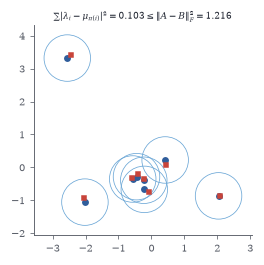

In [2]:
from scipy.optimize import linear_sum_assignment
from scipy.linalg import expm
rng = np.random.default_rng(3); n = 8
def rand_unitary(n):
    Z = rng.normal(size=(n, n)) + 1j * rng.normal(size=(n, n)); Q, R = np.linalg.qr(Z); return Q * (np.diag(R) / abs(np.diag(R)))
lamA = rng.normal(size=n) + 1j * rng.normal(size=n); U = rand_unitary(n); An = U @ np.diag(lamA) @ U.conj().T
Hs = rng.normal(size=(n, n)) + 1j * rng.normal(size=(n, n)); Hs = (Hs + Hs.conj().T) / 2; Rot = expm(0.06j * Hs)
Bn = Rot @ (U @ np.diag(lamA + 0.08 * (rng.normal(size=n) + 1j * rng.normal(size=n))) @ U.conj().T) @ Rot.conj().T
muB = np.linalg.eigvals(Bn); Cst = np.abs(lamA[:, None] - muB[None, :]) ** 2; r_, c_ = linear_sum_assignment(Cst); dAB = np.linalg.norm(An - Bn, 2)
fig, ax = plt.subplots(figsize=(W * 0.55, W * 0.5))
for i, j in zip(r_, c_): ax.plot([lamA[i].real, muB[j].real], [lamA[i].imag, muB[j].imag], color=GRAY, lw=0.8)
for z in lamA: ax.add_patch(plt.Circle((z.real, z.imag), dAB, fill=False, color=SKY, lw=0.5))
ax.plot(lamA.real, lamA.imag, "o", color=BLUE, ms=3.5); ax.plot(muB.real, muB.imag, "s", color=RED, ms=2.5); ax.set_aspect("equal")
ax.set_title(rf"$\sum|\lambda_i-\mu_{{\pi(i)}}|^2={Cst[r_, c_].sum():.3f}\leq\|A-B\|_F^2={np.linalg.norm(An - Bn)**2:.3f}$", fontsize=6)

Hölder continuity with exponent $1/n$. Left: eigenvalues of $J_8(0)+\varepsilon E$ for random perturbations $E$ with $\lVert E\rVert=1$ and $\varepsilon=10^{-12},10^{-8},10^{-4}$ (colours): they spread on rings of radius about $\varepsilon^{1/8}$, not $\varepsilon$. Right: the largest eigenvalue displacement against $\varepsilon$ for $J_8$ (blue, slope $\frac18$), compared with a normal matrix (red, slope $1$), and Elsner's bound (dashed).

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


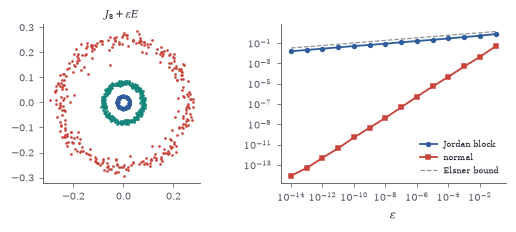

In [3]:
n = 8; J8 = np.eye(n, k=1); rng = np.random.default_rng(5)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0))
for eps, col in [(1e-12, BLUE), (1e-8, TEAL), (1e-4, RED)]:
    for _ in range(40):
        E = rng.normal(size=(n, n)) + 1j * rng.normal(size=(n, n)); E /= np.linalg.norm(E, 2); ev = np.linalg.eigvals(J8 + eps * E); axs[0].plot(ev.real, ev.imag, ".", color=col, ms=1.5)
axs[0].set_aspect("equal"); axs[0].set_title(r"$J_8+\varepsilon E$", fontsize=6.5)
epss = np.logspace(-14, -1, 14); dj, dn = [], []; Nm = np.diag(np.exp(2j * np.pi * np.arange(n) / n))
for eps in epss:
    wj, wn = 0, 0
    for _ in range(20):
        E = rng.normal(size=(n, n)) + 1j * rng.normal(size=(n, n)); E /= np.linalg.norm(E, 2)
        wj = max(wj, np.abs(np.linalg.eigvals(J8 + eps * E)).max()); ev = np.linalg.eigvals(Nm + eps * E); wn = max(wn, np.abs(ev[:, None] - np.diag(Nm)[None, :]).min(1).max())
    dj.append(wj); dn.append(wn)
axs[1].loglog(epss, dj, "o-", color=BLUE, ms=2.5, label="Jordan block"); axs[1].loglog(epss, dn, "s-", color=RED, ms=2.5, label="normal")
axs[1].loglog(epss, 2 ** (1 - 1 / n) * epss ** (1 / n), "--", color=GRAY, lw=0.8, label="Elsner bound"); axs[1].set_xlabel(r"$\varepsilon$"); axs[1].legend(fontsize=5.5)

Eigenvalue condition numbers predict sensitivity. For an upper triangular $10\times10$ matrix with eigenvalues $1,\dots,10$ on the diagonal and large random entries above it, the eigenvalues of $A+E$ for $200$ random $E$ with $\lVert E\rVert=10^{-8}$ move by different amounts (left: the displacement of each eigenvalue for each $E$, on a log scale, with black bars at $\kappa(\lambda)\lVert E\rVert$). Right: the observed cloud radius against $\kappa(\lambda)\lVert E\rVert$. The points follow the diagonal (slightly below it, since random perturbations are not the worst case): sensitivity varies by orders of magnitude between eigenvalues of the same matrix, exactly as $\kappa(\lambda)$ predicts.

Text(0, 0.5, 'observed radius')

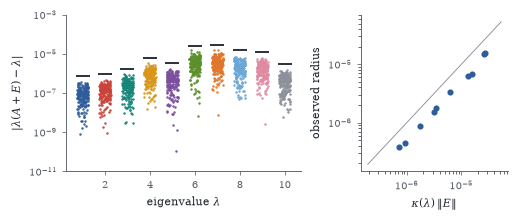

In [4]:
from matplotlib.ticker import LogLocator, NullFormatter
rng = np.random.default_rng(8); n = 10; Tm = np.diag(np.arange(1.0, n + 1)) + np.triu(rng.normal(size=(n, n)) * np.geomspace(0.3, 30, n)[None, :], 1)
ev, Vr = np.linalg.eig(Tm); evl, Vl = np.linalg.eig(Tm.T); order = np.argsort(ev.real); ev, Vr = ev[order], Vr[:, order]; Vl = Vl[:, np.argsort(evl.real)]
kap = np.array([np.linalg.norm(Vr[:, i]) * np.linalg.norm(Vl[:, i]) / abs(Vl[:, i] @ Vr[:, i]) for i in range(n)])
eps = 1e-8; clouds = []
for _ in range(200):
    E = rng.normal(size=(n, n)); E *= eps / np.linalg.norm(E, 2); e2 = np.linalg.eigvals(Tm + E); clouds.append(e2[np.argsort(e2.real)])
clouds = np.array(clouds); dev = np.abs(clouds - ev[None, :]); rad = dev.max(0)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.9), gridspec_kw={"width_ratios": [1.6, 1]})
for i in range(n): axs[0].semilogy(ev[i].real + rng.uniform(-0.25, 0.25, 200), dev[:, i] + 1e-18, ".", color=PALETTE[i % 10], ms=1.2)
axs[0].plot(ev.real, kap * eps, "_", color=INK, ms=9, mew=1.2); axs[0].set_xlabel(r"eigenvalue $\lambda$"); axs[0].set_ylabel(r"$|\lambda(A+E)-\lambda|$"); axs[0].set_ylim(1e-11, 1e-3)
axs[1].loglog(kap * eps, rad, "o", color=BLUE, ms=3); lim = [min(kap.min() * eps, rad.min()) / 2, max(kap.max() * eps, rad.max()) * 2]; axs[1].plot(lim, lim, color=GRAY, lw=0.6)
for ax_ in (axs[1].xaxis, axs[1].yaxis): ax_.set_major_locator(LogLocator(base=10, numticks=4)); ax_.set_minor_formatter(NullFormatter())
axs[1].set_xlabel(r"$\kappa(\lambda)\,\|E\|$"); axs[1].set_ylabel("observed radius")

In [5]:
from itertools import permutations
rng = np.random.default_rng(1); worst = 0
for _ in range(300):
    U5 = rand_unitary(5); Hh = rng.normal(size=(5, 5)) + 1j * rng.normal(size=(5, 5)); Hh = (Hh + Hh.conj().T) / 2; V5 = U5 @ expm(1j * rng.uniform(0.05, 0.6) * Hh)
    la, mu = np.linalg.eigvals(U5), np.linalg.eigvals(V5); d = min(max(abs(la - mu[list(p)])) for p in permutations(range(5)))
    worst = max(worst, d / np.linalg.norm(U5 - V5, 2))
print("max over 300 pairs of d(sigma(U), sigma(V)) / ||U - V||:", round(worst, 4))

max over 300 pairs of d(sigma(U), sigma(V)) / ||U - V||: 0.8858
